# ICU LOS v2 — Tahap 01: kohort, audit, dan pemisahan X / y
**Jalankan sel berurutan melalui Run All.** Notebook ini berdiri sendiri; tidak memerlukan berkas `.py` proyek lama.

Kohort: usia **≥18 tahun saat INTIME**, total ICU LOS **>4 jam**. Semua ICU stay yang memenuhi syarat dipertahankan, termasuk stay berulang dan pasien meninggal. Tidak ada seleksi first stay, kelengkapan demografi, atau missingness >30% dari Fan yang ditambahkan.

Perubahan rancangan: prediksi pertama jam ke-4, lalu setiap jam **selama masih di ICU**. Pada waktu prediksi t, input nantinya hanya berasal dari informasi yang tersedia **sebelum t**. Target tetap total ICU LOS, bukan sisa LOS. Tidak menggunakan observasi tetap 24/48 jam dan tidak memasukkan lama riwayat aktual sampai keluar sebagai fitur.

**Tahap ini belum mengekstraksi kejadian, membuat graf, split, embedding, atau training.** Hasil klinis dihasilkan hanya ketika notebook dijalankan pada PC yang menyimpan MIMIC. Notebook unduhan tidak berisi data pasien.

## 1. Konfigurasi
Dependensi: `numpy`, `pandas`, `matplotlib`, `IPython`. Pilih kernel Python yang sama dengan proyekmu. Bila import gagal, jalankan `%pip install numpy pandas matplotlib` pada sel baru, lalu restart kernel.

Folder data mentah hanya dibaca. Hasil tiap eksekusi disimpan sebagai run baru agar tidak menimpa versi 1 atau run sebelumnya. Pemeriksaan menggunakan kohort versi 1 untuk mempertahankan aturan usia; bila file tersebut tidak ditemukan, perbaiki `V1_COHORT` sebelum melanjutkan.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(os.environ.get("ICU_LOS_ROOT", r"C:\Users\ASUS\Documents\icu_los"))
RAW_ROOT = Path(os.environ.get("ICU_LOS_RAW_ROOT", r"C:\Users\ASUS\Documents\dgt_los\data\raw"))
V1_COHORT = Path(os.environ.get("ICU_LOS_V1_COHORT", r"C:\Users\ASUS\Documents\dgt_los\outputs\02_cohort\20261007_182445_393070_build\cohort_main_48h.csv"))
MIN_AGE_YEARS = 18
MIN_LOS_HOURS_EXCLUSIVE = 4
FIRST_PREDICTION_HOUR = 4
PREDICTION_INTERVAL_HOURS = 1
SHOW_LOCAL_PATIENT_PREVIEW = False  # True: tampilkan 5 baris lokal; jangan bagikan output berisi ID/diagnosis.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f") + "_cohort"
DATA_DIR = PROJECT_ROOT / "data" / RUN_ID
REPORT_DIR = PROJECT_ROOT / "outputs" / RUN_ID

assert PROJECT_ROOT.resolve() != RAW_ROOT.resolve()
assert MIN_AGE_YEARS == 18 and MIN_LOS_HOURS_EXCLUSIVE == 4
assert FIRST_PREDICTION_HOUR == 4 and PREDICTION_INTERVAL_HOURS == 1
for p in (DATA_DIR, REPORT_DIR):
    p.mkdir(parents=True, exist_ok=False)
print("Project:", PROJECT_ROOT)
print("Run:", RUN_ID)
print("Sumber data:", RAW_ROOT)

Project: C:\Users\ASUS\Documents\icu_los
Run: 20261019_134016_937053_cohort
Sumber data: C:\Users\ASUS\Documents\dgt_los\data\raw


## 2. Fungsi pembacaan dan integritas sumber
Mendukung satu file `.csv` atau `.csv.gz` untuk masing-masing PATIENTS, ADMISSIONS, ICUSTAYS. Jika kedua format ditemukan sekaligus, notebook berhenti agar sumber tidak dipilih secara diam-diam. Hash seluruh tiga file dicatat. Duplikasi kunci, ID tidak valid, atau ketidaksesuaian pasien–admission menghentikan proses.

In [2]:
def require(ok, message):
    if not bool(ok):
        raise ValueError(message)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def resolve_raw(table):
    hits = [p for p in RAW_ROOT.iterdir() if p.is_file() and p.name.upper() in {table + ".CSV", table + ".CSV.GZ"}]
    require(len(hits) == 1, f"{table}: harus ada tepat satu CSV/CSV.GZ; ditemukan {len(hits)}")
    return hits[0]

def read_columns(path, columns):
    frame = pd.read_csv(path, dtype="string", usecols=columns, keep_default_na=False)
    return frame.replace(r"^\s*$", pd.NA, regex=True)

def checked_ids(frame, cols):
    for col in cols:
        values = pd.to_numeric(frame[col], errors="coerce")
        require(values.notna().all() and values.gt(0).all() and values.mod(1).eq(0).all(), f"ID invalid: {col}")
        frame[col] = values.astype("int64")

def parse_time(series):
    return pd.to_datetime(series, format="%Y-%m-%d %H:%M:%S", errors="coerce")

sources = {t: resolve_raw(t) for t in ("PATIENTS", "ADMISSIONS", "ICUSTAYS")}
require(V1_COHORT.is_file(), "Kohort v1 tidak ditemukan. Perbaiki V1_COHORT agar aturan usia dapat diverifikasi.")
all_sources = {**sources, "V1_COHORT": V1_COHORT}
source_inventory = []
for name, path in all_sources.items():
    st = path.stat()
    source_inventory.append({"source": name, "path": str(path.resolve()), "bytes": st.st_size,
                             "mtime_ns": st.st_mtime_ns, "sha256": sha256(path)})
source_inventory = pd.DataFrame(source_inventory)
display(source_inventory[["source", "bytes", "sha256"]])

patients = read_columns(sources["PATIENTS"], ["SUBJECT_ID", "GENDER", "DOB"])
admissions = read_columns(sources["ADMISSIONS"], ["SUBJECT_ID", "HADM_ID", "ADMITTIME", "DISCHTIME", "ADMISSION_TYPE", "DIAGNOSIS"])
stays = read_columns(sources["ICUSTAYS"], ["SUBJECT_ID", "HADM_ID", "ICUSTAY_ID", "INTIME", "OUTTIME", "FIRST_CAREUNIT", "LOS"])
checked_ids(patients, ["SUBJECT_ID"])
checked_ids(admissions, ["SUBJECT_ID", "HADM_ID"])
checked_ids(stays, ["SUBJECT_ID", "HADM_ID", "ICUSTAY_ID"])
require(patients.SUBJECT_ID.is_unique, "PATIENTS.SUBJECT_ID duplikat")
require(admissions.HADM_ID.is_unique, "ADMISSIONS.HADM_ID duplikat")
require(stays.ICUSTAY_ID.is_unique, "ICUSTAYS.ICUSTAY_ID duplikat")
display(pd.DataFrame({"table": list(sources), "rows": [len(patients), len(admissions), len(stays)]}))

,source,bytes,sha256
0,PATIENTS,2628900,c11bc91be6d15aba5b2586072bae3d3b8ecf3e44106de9...
1,ADMISSIONS,12548562,a9480d0ffa83b8e0024f79f007a4fc432e1f2695973191...
2,ICUSTAYS,6357077,9d5db0223cb7638557d8afafda20e7a5f0dc833ec80dc2...
3,V1_COHORT,6102310,842e11f8e5a81a5df8267df6baee379516887ae6145610...


,table,rows
0,PATIENTS,46520
1,ADMISSIONS,58976
2,ICUSTAYS,61532


## 3. Pengaitan dan waktu
Gunakan ICUSTAY_ID sebagai unit kohort. Tidak membuang stay berulang. Timestamp ICU harus valid dan OUTTIME > INTIME untuk menghitung target. Kejanggalan hubungan waktu ICU dengan rawat inap rumah sakit dilaporkan sebagai temuan; tidak otomatis menggugurkan stay.

Diagnosis menggunakan ADMITTIME sebagai **proxy** waktu ketersediaan, mengikuti versi 1. Proxy tidak membuktikan kapan diagnosis dicatat. Diagnosis yang terlambat tidak boleh terlihat pada prediksi sebelumnya.

In [3]:
joined = stays.rename(columns={"LOS": "source_icu_los_days"}).merge(
    patients, on="SUBJECT_ID", how="left", validate="many_to_one", indicator="_patient_link")
joined = joined.merge(admissions.rename(columns={"SUBJECT_ID": "admission_SUBJECT_ID"}),
                      on="HADM_ID", how="left", validate="many_to_one", indicator="_admission_link")
require(joined._patient_link.eq("both").all(), "Ada ICU stay tanpa PATIENTS: periksa sumber; kohort tidak diterbitkan")
require(joined._admission_link.eq("both").all(), "Ada ICU stay tanpa ADMISSIONS: periksa sumber; kohort tidak diterbitkan")
require(joined.SUBJECT_ID.eq(joined.admission_SUBJECT_ID).all(), "Pasien ICUSTAYS tidak cocok dengan ADMISSIONS")
for col in ["DOB", "INTIME", "OUTTIME", "ADMITTIME", "DISCHTIME"]:
    joined[col] = parse_time(joined[col])
joined["source_icu_los_days"] = pd.to_numeric(joined.source_icu_los_days, errors="coerce")
joined["duration_seconds"] = (joined.OUTTIME - joined.INTIME).dt.total_seconds()
joined["total_icu_los_days"] = joined.duration_seconds / 86400.0
joined["icu_los_hours"] = joined.duration_seconds / 3600.0
joined["valid_icu_interval"] = joined.INTIME.notna() & joined.OUTTIME.notna() & joined.duration_seconds.gt(0)
# datetime64[s] menghindari overflow selisih nanodetik untuk DOB yang digeser ~300 tahun.
intime_seconds = joined.INTIME.to_numpy(dtype="datetime64[s]")
dob_seconds = joined.DOB.to_numpy(dtype="datetime64[s]")
age_seconds = (intime_seconds - dob_seconds).astype("timedelta64[s]").astype("float64")
age_seconds[joined.INTIME.isna() | joined.DOB.isna()] = np.nan
joined["age_proxy_unmasked"] = age_seconds / (365.2425 * 86400)
joined["age_topcoded"] = joined.age_proxy_unmasked.ge(200).astype("int8")

## 4. Pertahankan aturan usia versi 1
Notebook mencocokkan rumus usia dalam tahun penuh atau tahun pecahan dengan seluruh stay yang sama pada kohort v1. Nilai untuk usia yang disamarkan diperoleh dari `age_topcoded` v1, tidak ditebak. Jika tidak ada aturan yang cocok atau aturan yang sama-sama cocok menghasilkan usia berbeda pada calon kohort v2, proses berhenti dan meminta kode usia versi 1 untuk memastikan konsistensi.

Usia mentah sekitar 300 tahun akibat deidentifikasi tidak dianggap sebagai usia biologis dan tidak dikeluarkan karena nilainya besar. `age_topcoded` disimpan sebagai metadata, bukan fitur baru.

In [4]:
v1 = pd.read_csv(V1_COHORT, usecols=["ICUSTAY_ID", "SUBJECT_ID", "HADM_ID", "age_years", "age_topcoded"])
checked_ids(v1, ["ICUSTAY_ID", "SUBJECT_ID", "HADM_ID"])
require(v1.ICUSTAY_ID.is_unique, "Kohort v1 memiliki ID stay duplikat")
for col in ["age_years", "age_topcoded"]:
    v1[col] = pd.to_numeric(v1[col], errors="coerce")
require(v1.age_years.notna().all() and v1.age_topcoded.isin([0, 1]).all(), "Metadata usia kohort v1 tidak valid")
shared = joined.merge(v1, on="ICUSTAY_ID", suffixes=("", "_v1"), validate="one_to_one")
require(len(shared) == len(v1), "Tidak semua stay kohort v1 ditemukan dalam sumber raw ini")
require(shared.SUBJECT_ID.eq(shared.SUBJECT_ID_v1).all() and shared.HADM_ID.eq(shared.HADM_ID_v1).all(), "Identitas kohort v1 berbeda dari raw")
require(shared.age_topcoded.eq(shared.age_topcoded_v1).all(), "Aturan usia disamarkan v1 tidak cocok dengan batas >=200; periksa kode v1")
masked_values = v1.loc[v1.age_topcoded.eq(1), "age_years"].unique()
require(len(masked_values) == 1, "Nilai topcode v1 tidak unik/tidak tersedia; diperlukan kode usia v1")
TOPCODE_AGE = float(masked_values[0])
require(89 <= TOPCODE_AGE < 200, "Nilai topcode v1 di luar rentang representasi yang diharapkan")
calendar_age = (joined.INTIME.dt.year - joined.DOB.dt.year - (
    (joined.INTIME.dt.month < joined.DOB.dt.month) |
    ((joined.INTIME.dt.month == joined.DOB.dt.month) & (joined.INTIME.dt.day < joined.DOB.dt.day))).astype(int))
age_candidates = {"calendar_completed_years": calendar_age.to_numpy(dtype=float)}
for days in [365.2425, 365.25, 365.0]:
    age_candidates[f"floor_seconds_div_{days}_days"] = np.floor(age_seconds / (days * 86400))
    age_candidates[f"fractional_seconds_div_{days}_days"] = age_seconds / (days * 86400)
# Beberapa implementasi membagi jumlah hari bulat, bukan detik.
whole_day_age = (joined.INTIME.to_numpy(dtype="datetime64[D]") - joined.DOB.to_numpy(dtype="datetime64[D]")).astype("timedelta64[D]").astype(float)
whole_day_age[joined.INTIME.isna() | joined.DOB.isna()] = np.nan
for days in [365.2425, 365.25, 365.0]:
    age_candidates[f"floor_date_days_div_{days}"] = np.floor(whole_day_age / days)
    age_candidates[f"fractional_date_days_div_{days}"] = whole_day_age / days
positions = pd.Series(np.arange(len(joined)), index=joined.ICUSTAY_ID).loc[v1.ICUSTAY_ID].to_numpy()
matching = []
age_rule_rows = []
for name, values in age_candidates.items():
    values = np.where(joined.age_topcoded.eq(1), TOPCODE_AGE, values)
    age_candidates[name] = values
    matched = np.isclose(values[positions], v1.age_years.to_numpy(), atol=1e-8, rtol=0)
    age_rule_rows.append({"candidate": name, "shared_stays": len(v1), "matches": int(matched.sum()), "all_match": bool(matched.all())})
    if matched.all():
        matching.append(name)
require(matching, "Tidak ada rumus usia cocok sepenuhnya. Berikan kode usia STEP02 v1; jangan mengubah usia diam-diam.")
AGE_RULE = matching[0]
reference_ages = age_candidates[AGE_RULE]
relevant = joined.valid_icu_interval & joined.icu_los_hours.gt(MIN_LOS_HOURS_EXCLUSIVE)
for name in matching[1:]:
    require(np.allclose(reference_ages[relevant], age_candidates[name][relevant], atol=1e-8, rtol=0, equal_nan=True),
            "Beberapa rumus cocok pada v1 tetapi berbeda pada v2; diperlukan kode usia v1")
joined["age_years"] = reference_ages
joined["valid_age"] = np.isfinite(reference_ages) & (reference_ages >= 0)
age_rule_profile = pd.DataFrame(age_rule_rows)
display(age_rule_profile)
print("Aturan usia:", AGE_RULE, "| topcode dari v1:", TOPCODE_AGE)

,candidate,shared_stays,matches,all_match
0,calendar_completed_years,28919,28919,True
1,floor_seconds_div_365.2425_days,28919,28868,False
2,fractional_seconds_div_365.2425_days,28919,1412,False
3,floor_seconds_div_365.25_days,28919,28856,False
4,fractional_seconds_div_365.25_days,28919,1412,False
5,floor_seconds_div_365.0_days,28919,27784,False
6,fractional_seconds_div_365.0_days,28919,1412,False
7,floor_date_days_div_365.2425,28919,28855,False
8,fractional_date_days_div_365.2425,28919,1412,False
9,floor_date_days_div_365.25,28919,28835,False


Aturan usia: calendar_completed_years | topcode dari v1: 90.0


## 5. Seleksi kohort dan ringkasan ketersediaan diagnosis
Eksklusi berurutan sehingga hitungan dapat direkonsiliasi: interval ICU tidak valid → usia tidak valid → usia <18 → LOS ≤4 jam. Tidak ada pemangkasan LOS panjang, pengecualian mortalitas, atau syarat memiliki teks.

`first_prediction_time` hanya jadwal prediksi awal. `last_prediction_hour` dan `eligible_prediction_count` adalah metadata penjadwalan/evaluasi, **bukan fitur X**. OUTTIME hanya menentukan target dan kelayakan titik prediksi offline.

In [5]:
flow_rows = [{"stage": "ICUSTAYS input", "before": len(joined), "excluded": 0, "remaining": len(joined)}]
keep = pd.Series(True, index=joined.index)
joined["exclusion_reason"] = "included"
filters = [
    ("invalid_ICU_interval", joined.valid_icu_interval),
    ("invalid_age", joined.valid_age),
    ("age_below_18", joined.age_years.ge(MIN_AGE_YEARS)),
    ("ICU_LOS_not_above_4h", joined.icu_los_hours.gt(MIN_LOS_HOURS_EXCLUSIVE)),
]
for reason, eligible in filters:
    before = int(keep.sum())
    rejected = keep & ~eligible
    joined.loc[rejected, "exclusion_reason"] = reason
    keep &= eligible
    flow_rows.append({"stage": reason, "before": before, "excluded": int(rejected.sum()), "remaining": int(keep.sum())})
cohort = joined.loc[keep].copy().sort_values("ICUSTAY_ID").reset_index(drop=True)
require(len(cohort) > 0, "Kohort kosong")
cohort["cohort_row"] = np.arange(len(cohort), dtype="int64")
cohort["first_prediction_time"] = cohort.INTIME + pd.Timedelta(hours=FIRST_PREDICTION_HOUR)
cohort["first_prediction_hour"] = FIRST_PREDICTION_HOUR
cohort["last_prediction_hour"] = np.ceil(cohort.icu_los_hours).astype("int64") - 1
cohort["eligible_prediction_count"] = cohort.last_prediction_hour - FIRST_PREDICTION_HOUR + 1
cohort["DIAGNOSIS_AVAILABLE_TIME_PROXY"] = cohort.ADMITTIME
cohort["diagnosis_present"] = cohort.DIAGNOSIS.fillna("").str.strip().ne("").astype("int8")
cohort["diagnosis_available_hour"] = (cohort.DIAGNOSIS_AVAILABLE_TIME_PROXY - cohort.INTIME).dt.total_seconds() / 3600
cohort["diagnosis_available_at_4h"] = (cohort.diagnosis_present.eq(1) & cohort.diagnosis_available_hour.lt(4)).astype("int8")
flow = pd.DataFrame(flow_rows)
display(flow)

los_band = pd.cut(cohort.icu_los_hours, bins=[4, 24, 48, 72, 168, np.inf], right=True,
                  labels=[">4–24h", ">24–48h", ">48–72h", ">72h–7d", ">7d"])
los_groups = los_band.value_counts(sort=False).rename_axis("LOS_group").reset_index(name="icu_stays")
los_groups["percentage"] = 100 * los_groups.icu_stays / len(cohort)
los_summary = cohort.total_icu_los_days.describe(percentiles=[.25, .5, .75, .90, .95, .99]).rename_axis("metric").reset_index(name="value_days")
coverage = pd.DataFrame([
    {"prediction_hour": h, "eligible_stays": int(cohort.icu_los_hours.gt(h).sum())}
    for h in [4, 6, 12, 24, 48, 72, 168]
])
display(los_groups)
display(los_summary)
display(coverage)

,stage,before,excluded,remaining
0,ICUSTAYS input,61532,0,61532
1,invalid_ICU_interval,61532,10,61522
2,invalid_age,61522,0,61522
3,age_below_18,61522,8193,53329
4,ICU_LOS_not_above_4h,53329,285,53044


,LOS_group,icu_stays,percentage
0,>4–24h,7794,14.693462
1,>24–48h,16331,30.787648
2,>48–72h,9385,17.692859
3,>72h–7d,12081,22.775432
4,>7d,7453,14.050600


,metric,value_days
0,count,53044.000000
1,mean,4.167629
2,std,6.166579
3,min,0.166771
4,25%,1.217115
5,50%,2.154861
6,75%,4.206991
7,90%,9.178216
8,95%,14.808365
9,99%,31.251461


,prediction_hour,eligible_stays
0,4,53044
1,6,52904
2,12,52286
3,24,45250
4,48,28919
5,72,19534
6,168,7453


## 6. X dan y yang terpisah
Seperti alur kode pembanding: pilih target → keluarkan target dari fitur → bentuk X dan y. Tahap ini membuat **X statis mentah** (4 kolom); one-hot/normalisasi dikerjakan pada tahap 03 dengan train tiap fold. Karena itu X belum berupa 17 kolom hasil encoding versi lama.

Diagnosis menjadi masukan teks terpisah dengan proxy availability. Temporal dan NOTEEVENTS belum dibaca pada tahap ini. Seluruh 43 fitur temporal sebelumnya tercantum pada kontrak untuk tahap berikutnya.

`ICUSTAY_ID`, `SUBJECT_ID`, `HADM_ID`, OUTTIME, LOS sumber, target, jumlah prediksi, dan panjang sequence aktual **tidak boleh masuk X**. Tidak melakukan normalisasi atau log-transform target.

In [6]:
STATIC_FEATURES = ["age_years", "GENDER", "ADMISSION_TYPE", "FIRST_CAREUNIT"]
TARGET = "total_icu_los_days"
TEMPORAL_FEATURES = [
 "heart_rate", "systolic_bp", "diastolic_bp", "mean_bp", "respiratory_rate", "spo2", "temperature", "chart_glucose",
 "gcs_eye", "gcs_verbal", "gcs_motor", "gcs_total_recorded", "lab_glucose", "sodium", "potassium", "chloride",
 "bicarbonate", "bun", "creatinine", "wbc", "hemoglobin", "hematocrit", "platelets", "lactate", "albumin",
 "bilirubin_total", "inr", "blood_ph", "blood_pco2", "blood_po2", "crystalloid_recorded_ml", "colloid_recorded_ml",
 "blood_product_recorded_ml", "oral_recorded_ml", "enteral_flush_recorded_ml", "parenteral_nutrition_recorded_ml",
 "urine_recorded_ml", "chest_drain_recorded_ml", "gastric_recorded_ml", "jp_drain_recorded_ml", "stool_ostomy_recorded_ml",
 "gu_irrigant_in_recorded_ml", "gu_irrigant_out_recorded_ml"]
ID_COLUMNS = ["ICUSTAY_ID", "SUBJECT_ID", "HADM_ID"]
# X/y memiliki urutan baris persis sama dengan cohort, tanpa ID sebagai fitur.
X_static = cohort.loc[:, STATIC_FEATURES].copy()
y = cohort[TARGET].to_numpy(dtype=np.float64, copy=True)
row_map = cohort[["cohort_row"] + ID_COLUMNS].copy()
X_diagnosis = cohort[["cohort_row", "DIAGNOSIS", "DIAGNOSIS_AVAILABLE_TIME_PROXY", "diagnosis_present", "diagnosis_available_hour"]].copy()
forbidden = set(ID_COLUMNS + [TARGET, "source_icu_los_days", "OUTTIME", "icu_los_hours", "duration_seconds", "last_prediction_hour", "eligible_prediction_count"])
require(not forbidden.intersection(X_static.columns), "ID/target/outcome metadata masuk X")
require(len(TEMPORAL_FEATURES) == 43 and len(set(TEMPORAL_FEATURES)) == 43, "Kontrak temporal tidak valid")
require(X_static.index.equals(cohort.index) and len(X_static) == len(y) == len(row_map), "X/y tidak sejajar")
require(np.isfinite(y).all() and (y > 4/24).all(), "Target y invalid")
print("X_static:", X_static.shape, "| kolom:", list(X_static.columns))
print("y:", y.shape, "| dtype:", y.dtype, "| unit: hari")
print("Diagnosis: terpisah untuk teks; temporal 43 fitur dan NOTEEVENTS menyusul tahap 02.")
if SHOW_LOCAL_PATIENT_PREVIEW:
    display(cohort[["cohort_row"] + ID_COLUMNS + STATIC_FEATURES + ["DIAGNOSIS", TARGET]].head())
else:
    display(pd.DataFrame({"component": ["X_static", "y", "row_map", "X_diagnosis"],
                          "rows": [len(X_static), len(y), len(row_map), len(X_diagnosis)],
                          "columns": [4, 1, 4, len(X_diagnosis.columns)]}))

X_static: (53044, 4) | kolom: ['age_years', 'GENDER', 'ADMISSION_TYPE', 'FIRST_CAREUNIT']
y: (53044,) | dtype: float64 | unit: hari
Diagnosis: terpisah untuk teks; temporal 43 fitur dan NOTEEVENTS menyusul tahap 02.


,component,rows,columns
0,X_static,53044,4
1,y,53044,1
2,row_map,53044,4
3,X_diagnosis,53044,5


## 7. Pemeriksaan kohort dan temuan audit
Keanehan waktu rumah sakit, diagnosis terlambat, demografi kosong, dan selisih LOS bawaan dilaporkan; tidak mengubah nilai atau menghapus stay secara otomatis. Batas >4 jam memakai timestamp ICU, sehingga pembulatan kolom LOS sumber tidak menentukan seleksi.

In [7]:
source_delta = (cohort.total_icu_los_days - cohort.source_icu_los_days).abs()
source_valid = np.isfinite(cohort.source_icu_los_days) & cohort.source_icu_los_days.gt(0)
findings_dict = {
 "cohort_stays": len(cohort), "unique_patients": cohort.SUBJECT_ID.nunique(), "unique_admissions": cohort.HADM_ID.nunique(),
 "patients_with_multiple_ICU_stays": int(cohort.groupby("SUBJECT_ID").size().gt(1).sum()),
 "admissions_with_multiple_ICU_stays": int(cohort.groupby("HADM_ID").size().gt(1).sum()),
 "age_topcoded": int(cohort.age_topcoded.sum()),
 "GENDER_missing": int(cohort.GENDER.isna().sum()), "ADMISSION_TYPE_missing": int(cohort.ADMISSION_TYPE.isna().sum()),
 "FIRST_CAREUNIT_missing": int(cohort.FIRST_CAREUNIT.isna().sum()),
 "diagnosis_missing": int(cohort.diagnosis_present.eq(0).sum()),
 "diagnosis_proxy_missing": int(cohort.ADMITTIME.isna().sum()),
 "diagnosis_proxy_after_ICU_entry": int(cohort.diagnosis_available_hour.gt(0).sum()),
 "diagnosis_available_at_4h": int(cohort.diagnosis_available_at_4h.sum()),
 "ICU_entry_before_hospital_admission": int(cohort.INTIME.lt(cohort.ADMITTIME).sum()),
 "ICU_exit_after_hospital_discharge": int(cohort.OUTTIME.gt(cohort.DISCHTIME).sum()),
 "hospital_discharge_before_admission": int(cohort.DISCHTIME.lt(cohort.ADMITTIME).sum()),
 "raw_LOS_missing_invalid_nonpositive": int((~source_valid).sum()),
 "current_vs_raw_LOS_max_abs_difference_days": float(source_delta[source_valid].max()) if source_valid.any() else None,
 "current_vs_raw_LOS_mean_abs_difference_days": float(source_delta[source_valid].mean()) if source_valid.any() else None,
 "eligible_hourly_prediction_points_offline": int(cohort.eligible_prediction_count.sum()),
}
findings = pd.DataFrame([{"metric": k, "value": v} for k, v in findings_dict.items()])
checks_list = []
def check(name, ok):
    checks_list.append({"check": name, "status": "PASS" if bool(ok) else "FAIL"})
check("unique_positive_ICUSTAY_ID", cohort.ICUSTAY_ID.is_unique and cohort.ICUSTAY_ID.gt(0).all())
check("source_joins_and_subject_admission_alignment", cohort.SUBJECT_ID.eq(cohort.admission_SUBJECT_ID).all())
check("adult_age_at_ICU_entry", cohort.age_years.ge(18).all())
check("positive_valid_ICU_intervals_above_4h", cohort.valid_icu_interval.all() and cohort.icu_los_hours.gt(4).all())
check("target_exactly_OUTTIME_minus_INTIME_days", np.array_equal(y, (cohort.OUTTIME-cohort.INTIME).dt.total_seconds().to_numpy()/86400))
check("X_y_order_and_length", len(X_static) == len(y) == len(row_map) and np.array_equal(row_map.ICUSTAY_ID, cohort.ICUSTAY_ID))
check("X_excludes_ID_target_and_outcome_metadata", not forbidden.intersection(X_static.columns))
check("all_retained_stays_have_prediction_at_4h", cohort.first_prediction_time.lt(cohort.OUTTIME).all() and cohort.eligible_prediction_count.ge(1).all())
last_time = cohort.INTIME + pd.to_timedelta(cohort.last_prediction_hour, unit="h")
check("last_grid_prediction_strictly_before_exit", last_time.lt(cohort.OUTTIME).all())
check("next_grid_point_not_before_exit", (last_time + pd.Timedelta(hours=1)).ge(cohort.OUTTIME).all())
check("selection_counts_reconciled", len(cohort)+int(flow.excluded.sum()) == len(joined))
check("v1_age_rules_reproduced", np.allclose(joined.set_index("ICUSTAY_ID").loc[v1.ICUSTAY_ID, "age_years"], v1.age_years, atol=1e-8, rtol=0))
check("no_other_clinical_exclusions", int(keep.sum()) == int((joined.valid_icu_interval & joined.valid_age & joined.age_years.ge(18) & joined.icu_los_hours.gt(4)).sum()))
check("all_eligible_repeated_stays_retained", set(cohort.ICUSTAY_ID) == set(joined.loc[keep, "ICUSTAY_ID"]))
for _, src in source_inventory.iterrows():
    p = Path(src.path)
    check("unchanged_" + src.source, p.stat().st_size == src.bytes and p.stat().st_mtime_ns == src.mtime_ns and sha256(p) == src.sha256)
checks = pd.DataFrame(checks_list)
display(checks)
display(findings)
checks.to_csv(REPORT_DIR / "quality_checks.csv", index=False)
require(checks.status.eq("PASS").all(), "Ada pemeriksaan FAIL. Data kohort tidak diterbitkan; periksa quality_checks.csv")

,check,status
0,unique_positive_ICUSTAY_ID,PASS
1,source_joins_and_subject_admission_alignment,PASS
2,adult_age_at_ICU_entry,PASS
3,positive_valid_ICU_intervals_above_4h,PASS
4,target_exactly_OUTTIME_minus_INTIME_days,PASS
5,X_y_order_and_length,PASS
6,X_excludes_ID_target_and_outcome_metadata,PASS
7,all_retained_stays_have_prediction_at_4h,PASS
8,last_grid_prediction_strictly_before_exit,PASS
9,next_grid_point_not_before_exit,PASS


,metric,value
0,cohort_stays,5.304400e+04
1,unique_patients,3.839800e+04
2,unique_admissions,4.953700e+04
3,patients_with_multiple_ICU_stays,8.440000e+03
4,admissions_with_multiple_ICU_stays,3.047000e+03
5,age_topcoded,2.699000e+03
6,GENDER_missing,0.000000e+00
7,ADMISSION_TYPE_missing,0.000000e+00
8,FIRST_CAREUNIT_missing,0.000000e+00
9,diagnosis_missing,1.000000e+00


## 8. Visualisasi hasil aktual
Grafik menggunakan seluruh kohort hasil run ini. Tidak memotong atau menghapus outlier. Panel histogram kedua membatasi tampilan sampai persentil ke-99 **hanya untuk keterbacaan**, tanpa mengubah data. Waktu dalam grafik terakhir adalah jam relatif sejak masuk ICU, bukan waktu kalender.

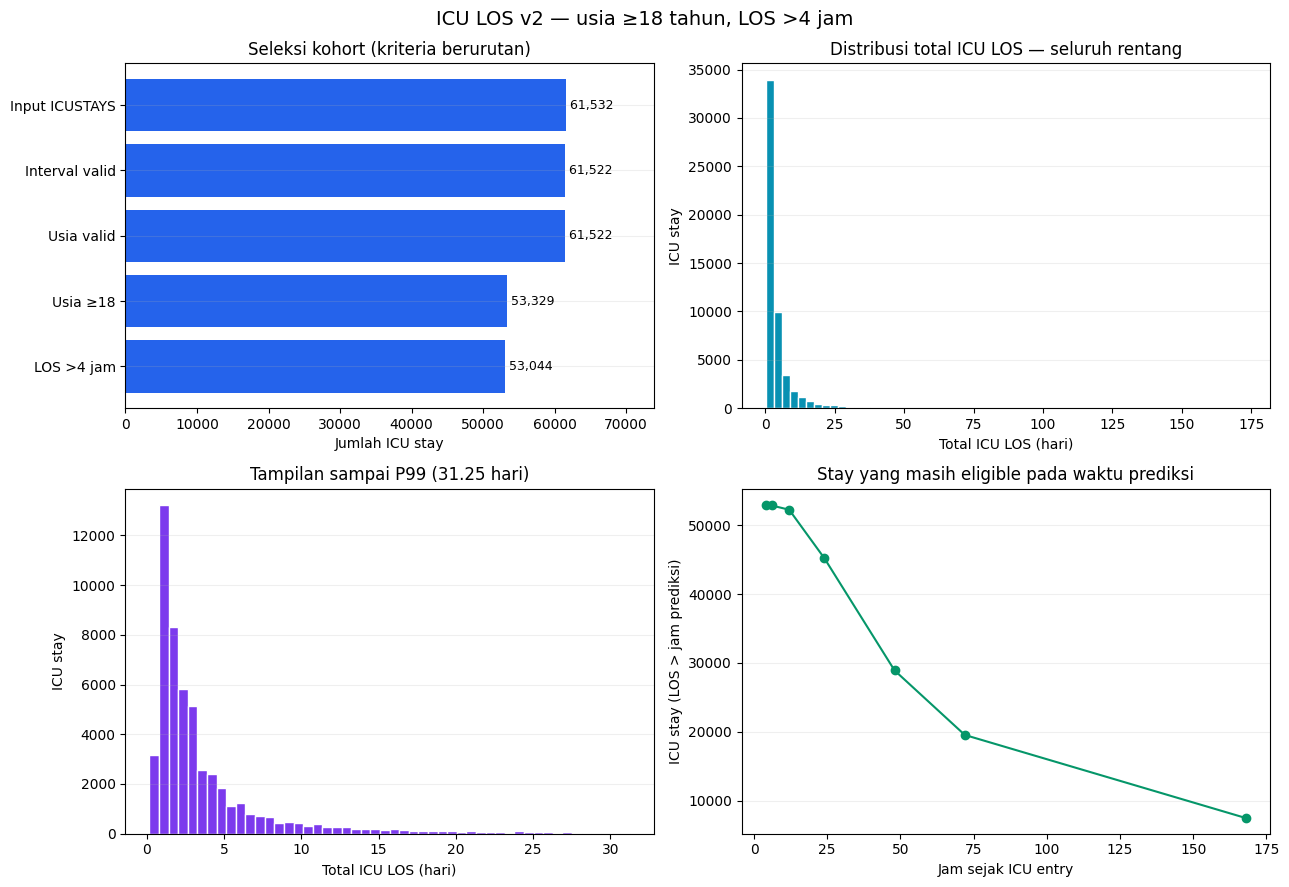

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
ax.barh(["Input ICUSTAYS", "Interval valid", "Usia valid", "Usia ≥18", "LOS >4 jam"], flow.remaining, color="#2563eb")
ax.invert_yaxis()
ax.set_title("Seleksi kohort (kriteria berurutan)")
ax.set_xlabel("Jumlah ICU stay")
for i, n in enumerate(flow.remaining):
    ax.text(n, i, f" {n:,}", va="center", fontsize=9)
ax.set_xlim(0, max(flow.remaining)*1.2)
axes[0, 1].hist(y, bins=60, color="#0891b2", edgecolor="white")
axes[0, 1].set(title="Distribusi total ICU LOS — seluruh rentang", xlabel="Total ICU LOS (hari)", ylabel="ICU stay")
p99 = float(np.quantile(y, .99))
axes[1, 0].hist(y[y <= p99], bins=50, color="#7c3aed", edgecolor="white")
axes[1, 0].set(title=f"Tampilan sampai P99 ({p99:.2f} hari)", xlabel="Total ICU LOS (hari)", ylabel="ICU stay")
axes[1, 1].plot(coverage.prediction_hour, coverage.eligible_stays, marker="o", color="#059669")
axes[1, 1].set(title="Stay yang masih eligible pada waktu prediksi", xlabel="Jam sejak ICU entry", ylabel="ICU stay (LOS > jam prediksi)")
for ax in axes.flat:
    ax.grid(axis="y", alpha=.2)
fig.suptitle("ICU LOS v2 — usia ≥18 tahun, LOS >4 jam", fontsize=14)
fig.tight_layout()
fig.savefig(REPORT_DIR / "cohort_overview.png", dpi=180, bbox_inches="tight")
fig.savefig(REPORT_DIR / "cohort_overview.svg", bbox_inches="tight")
plt.show()

## 9. Simpan data lokal dan kontrak tahap berikutnya
Berkas berakhiran `_LOCAL` mencakup data pasien/diagnosis/target dan hanya disimpan pada PC yang berwenang. Laporan agregat tidak memuat ID pasien atau isi diagnosis. Jangan unggah tabel lokal untuk meminta bantuan; cukup bagikan summary dan quality_checks.

`X_static_raw_LOCAL.csv`, `y_total_icu_los_days_LOCAL.npy`, dan `row_map_LOCAL.csv` mempunyai urutan sama, ditetapkan oleh `cohort_row` pada kohort. Tahap split nanti membaca y secara terpisah dari fitur. Berkas `cohort_LOCAL.csv` boleh memiliki target dan metadata untuk inspeksi, tetapi bukan otomatis seluruh kolomnya dimasukkan ke model.

In [9]:
cohort_columns = ["cohort_row"] + ID_COLUMNS + ["INTIME", "OUTTIME", "first_prediction_time", "first_prediction_hour", "last_prediction_hour", "eligible_prediction_count",
 "age_years", "age_topcoded", "GENDER", "ADMISSION_TYPE", "FIRST_CAREUNIT", "DIAGNOSIS", "ADMITTIME", "DISCHTIME",
 "DIAGNOSIS_AVAILABLE_TIME_PROXY", "diagnosis_present", "diagnosis_available_hour", "diagnosis_available_at_4h", "source_icu_los_days", TARGET]
cohort.loc[:, cohort_columns].to_csv(DATA_DIR / "cohort_LOCAL.csv", index=False)
X_static.to_csv(DATA_DIR / "X_static_raw_LOCAL.csv", index=False)
np.save(DATA_DIR / "y_total_icu_los_days_LOCAL.npy", y, allow_pickle=False)
row_map.to_csv(DATA_DIR / "row_map_LOCAL.csv", index=False)
X_diagnosis.to_csv(DATA_DIR / "diagnosis_raw_LOCAL.csv", index=False)
joined.loc[~keep, ID_COLUMNS + ["exclusion_reason"]].to_csv(DATA_DIR / "excluded_stays_LOCAL.csv", index=False)
for name, frame in {"selection_flow": flow, "cohort_counts": findings, "target_distribution": los_summary,
                    "LOS_groups": los_groups, "prediction_time_coverage": coverage, "age_rule_comparison": age_rule_profile,
                    "source_inventory": source_inventory}.items():
    frame.to_csv(REPORT_DIR / f"{name}.csv", index=False)

contract = {
 "version": "icu_los_v2_stage01", "cohort_unit": "ICUSTAY_ID", "patient_group_key": "SUBJECT_ID",
 "inclusion": {"minimum_age_years": 18, "ICU_LOS_hours_strictly_greater_than": 4},
 "first_stay_only": False, "exclude_deaths": False, "require_text": False,
 "prediction": {"first_hour": 4, "interval_hours": 1, "eligible_if": "prediction_time < OUTTIME",
                "information_cutoff": "AVAILABLE_TIME strictly before prediction_time", "fixed_24_48_window": False,
                "forward_fill_scope": "past values within same ICU stay only; no future backfill",
                "post_discharge_padding": "never a predictive feature"},
 "static_raw_features": STATIC_FEATURES, "temporal_features": TEMPORAL_FEATURES,
 "text_sources": ["ADMISSIONS.DIAGNOSIS", "NOTEEVENTS.TEXT"],
 "diagnosis_proxy": "ADMITTIME; gate at actual proxy; do not duplicate diagnosis in numeric static branch",
 "notes_policy_inherited": {"exclude_categories": ["Discharge summary"], "exclude_ISERROR_1": True,
     "exclude_blank_text": True, "exclude_death_pattern_notes": True,
     "retain_LOS_and_completed_disposition_content": True,
     "availability": "max(CHARTTIME, STORETIME); missing STORETIME uses CHARTTIME with flag",
     "precise_time": "require CHARTTIME; never infer midnight from CHARTDATE"},
 "target": {"column": TARGET, "formula": "(OUTTIME-INTIME).total_seconds()/86400", "unit": "days",
            "role": "y only", "transform": "none", "source_ICUSTAYS_LOS": "audit comparator only"},
 "age_rule": AGE_RULE, "topcode_age_from_v1": TOPCODE_AGE, "age_topcoded_is_extra_feature": False,
 "future_preprocessing": "train only, separately per fold; no fit at stage01",
 "future_fusions": ["early", "intermediate", "late"],
 "future_model_families": ["LSTM", "StaticGraphTransformer", "DynamicGraphTransformer"],
 "text_embedding": {"model": "BioClinicalBERT", "frozen": True, "pooling": "mean content tokens"},
 "prediction_point_weighting": "not yet implemented; choose stay-balanced training and report stay-level plus time-specific metrics before training",
 "warnings": ["diagnosis/notes timestamps are availability proxies", "retained LOS/disposition text may reveal outcome information",
              "full-stay duration/count/exit time are scheduling/target metadata, not features",
              "full trajectory creates unequal prediction counts; do not silently overweight long stays"]
}
contract_path = REPORT_DIR / "input_contract.json"
contract_path.write_text(json.dumps(contract, indent=2, ensure_ascii=False), encoding="utf-8")
artifacts = []
for folder in [DATA_DIR, REPORT_DIR]:
    for path in sorted(folder.iterdir()):
        if path.is_file():
            artifacts.append({"path": str(path.resolve()), "bytes": path.stat().st_size, "sha256": sha256(path)})
metadata = {
 "version": "icu_los_v2_stage01", "stage": "cohort_audit", "status": "COHORT_COMPLETE_READY_FOR_SEQUENCE_BUILD",
 "run_id": RUN_ID, "created_utc": datetime.now(timezone.utc).isoformat(),
 "project_root": str(PROJECT_ROOT.resolve()), "data_directory": str(DATA_DIR.resolve()), "report_directory": str(REPORT_DIR.resolve()),
 "cohort_file": str((DATA_DIR / "cohort_LOCAL.csv").resolve()), "cohort_sha256": sha256(DATA_DIR / "cohort_LOCAL.csv"),
 "contract_file": str(contract_path.resolve()), "contract_sha256": sha256(contract_path),
 "source_inventory": source_inventory.to_dict("records"), "artifacts": artifacts,
 "counts": findings_dict, "settings": {"minimum_age": 18, "minimum_LOS_hours_exclusive": 4, "age_rule": AGE_RULE, "topcode_age": TOPCODE_AGE},
 "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__},
 "X_features": STATIC_FEATURES, "y_target": TARGET, "source_data_modified": False,
 "preprocessing_fit": False, "split_created": False, "training_performed": False,
}
(REPORT_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
summary = "\n".join([
 "ICU LOS v2 — STAGE01 COHORT AUDIT", f"Run: {RUN_ID}",
 "Inclusion: age >=18 at ICU entry; ICU LOS strictly >4h; repeated stays retained.",
 f"Cohort stays: {len(cohort):,}; unique patients: {cohort.SUBJECT_ID.nunique():,}",
 f"X_static raw: {X_static.shape}; y: {y.shape}; target total ICU LOS in days.",
 f"Age rule verified against v1: {AGE_RULE}; topcode: {TOPCODE_AGE}.",
 f"Prospective hourly prediction grid: first hour 4; offline eligible points: {cohort.eligible_prediction_count.sum():,}.",
 f"Checks: {checks.status.eq('PASS').sum()} PASS; {checks.status.eq('FAIL').sum()} FAIL.",
 "No event extraction, split, feature fitting, embedding, graph, training or test evaluation.",
 "Diagnosis availability is a proxy; LOS/disposition text retention policy remains a limitation.",
 "All local ID/diagnosis/target tables must stay on the authorized PC.",
 "Status: COHORT_COMPLETE_READY_FOR_SEQUENCE_BUILD", f"Data: {DATA_DIR}", f"Reports: {REPORT_DIR}"
])
(REPORT_DIR / "summary.txt").write_text(summary, encoding="utf-8")
print(summary)

ICU LOS v2 — STAGE01 COHORT AUDIT
Run: 20261019_134016_937053_cohort
Inclusion: age >=18 at ICU entry; ICU LOS strictly >4h; repeated stays retained.
Cohort stays: 53,044; unique patients: 38,398
X_static raw: (53044, 4); y: (53044,); target total ICU LOS in days.
Age rule verified against v1: calendar_completed_years; topcode: 90.0.
Prospective hourly prediction grid: first hour 4; offline eligible points: 5,120,055.
Checks: 18 PASS; 0 FAIL.
No event extraction, split, feature fitting, embedding, graph, training or test evaluation.
Diagnosis availability is a proxy; LOS/disposition text retention policy remains a limitation.
All local ID/diagnosis/target tables must stay on the authorized PC.
Status: COHORT_COMPLETE_READY_FOR_SEQUENCE_BUILD
Data: C:\Users\ASUS\Documents\icu_los\data\20261019_134016_937053_cohort
Reports: C:\Users\ASUS\Documents\icu_los\outputs\20261019_134016_937053_cohort


## 10. Lanjut tahap 02
Gunakan **run_metadata.json dari run ini** sebagai sumber kohort. Tahap berikutnya mengunci hash kohort dan kontrak sebelum membaca event.

Yang boleh dibagikan untuk review: `summary.txt`, `quality_checks.csv`, `cohort_counts.csv`, dan grafik agregat. Berkas `_LOCAL` tetap di PC. Simpan notebook setelah Run All agar tabel/grafik tetap terlihat saat dibuka kembali; menyimpan notebook tidak menyimpan seluruh memori kernel.

### Referensi dan batas adaptasi
- Fan et al. (2025), *ContrastLOS*, bagian III Dataset, halaman artikel 34138: sebagian kriteria yang diadaptasi ialah dewasa dan ICU LOS >4 jam. Rancangan prediksi per jam di sini adalah keputusan studi ini, bukan klaim replikasi prosedur Fan.
- MIMIC-III ICUSTAYS: https://mimic.mit.edu/docs/iii/tables/icustays.html
- MIMIC-III struktur tabel/identitas: https://mimic.mit.edu/docs/iii/tables/
- MIMIC-III diagnosis admisi: https://mimic.mit.edu/docs/iii/tables/admissions.html
- Deidentifikasi usia: https://mimic.mit.edu/docs/iii/tutorials/intro-to-mimic-iii.html